# Recuperación de información sobre BBC News

Notebook de entrega de la práctica. La lógica vive en `src/*.py`; aquí se importan y ejecutan esos scripts y se muestran las tablas y figuras de `reports/`.

Cada sección corresponde a una etapa del pipeline que ya pasó la validación de calidad (`reports/validacion/<etapa>.md`). Para reproducir el entorno, ver `ENTORNO.md`.

## 0. Setup

Estructura de carpetas, dependencias (`requirements.txt`) y entorno `bbc-ir` (Python 3.11). La celda siguiente ubica el notebook en la raíz del repositorio, agrega `src/` a la ruta de importación y comprueba las librerías.

In [1]:
import os, sys, json
from pathlib import Path
from importlib.metadata import version

# Raíz del repositorio: la carpeta que contiene src/ y estado/
RAIZ = Path.cwd()
while not (RAIZ / 'src').is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ / 'src') not in sys.path:
    sys.path.insert(0, str(RAIZ / 'src'))

import pandas as pd
import spacy
from IPython.display import Image, Markdown, display

spacy.load('en_core_web_sm')  # el corpus está en inglés
pd.set_option('display.max_colwidth', 80)

libs = ['pandas', 'numpy', 'scikit-learn', 'scipy', 'rank-bm25', 'gensim', 'spacy', 'nltk',
        'matplotlib', 'wordcloud', 'python-pptx', 'pyyaml', 'joblib']
print('Python', sys.version.split()[0])
pd.DataFrame({'libreria': libs, 'version': [version(l) for l in libs]})

Python 3.11.17


,libreria,version
0,pandas,3.0.6
1,numpy,2.4.6
2,scikit-learn,1.9.1
3,scipy,1.17.1
4,rank-bm25,0.2.2
5,gensim,4.4.0
6,spacy,3.8.16
7,nltk,3.10.3
8,matplotlib,3.11.2
9,wordcloud,1.9.6


In [2]:
# Estado del pipeline (fuente de verdad: estado/progreso.json)
progreso = json.load(open('estado/progreso.json'))
pd.DataFrame(progreso['etapas']).T[['estado', 'intentos', 'commit']]

,estado,intentos,commit
setup,PASS,0,679174d
descarga,PASS,0,32ea3e5
eda_raw,PASS,0,6eb45bf
limpieza,PASS,0,None
eda_corpus,PENDIENTE,0,None
indices,PENDIENTE,0,None
evaluacion,PENDIENTE,0,None
presentacion,PENDIENTE,0,None


## 1. Descarga

`src/descarga.py` obtiene `data/raw/bbc-text.csv` (si ya existe no lo vuelve a bajar), calcula su SHA-256 y verifica 2,225 filas y las 5 categorías esperadas.

In [3]:
import descarga

df_raw = descarga.main()

ya existe: /Users/mikitl/Documents/FES/Ciencia de Datos/Clases/míneriaTextos/BBC-News-Classification/data/raw/bbc-text.csv (5,059,719 bytes)
SHA-256: e7652d6aa0fa92b2d02c6a992ebda82281041f83e7c2a92ae6e9c1c444981a8d
shape: (2225, 2)
conteo por categoría:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
nulos por columna:
category    0
text        0
verificación OK


In [4]:
conteo = df_raw['category'].value_counts().rename_axis('categoria').reset_index(name='documentos')
conteo['porcentaje'] = (conteo['documentos'] / len(df_raw) * 100).map('{:.2f}%'.format)
print(f'Filas: {len(df_raw):,} | SHA-256:', open(descarga.RUTA_SHA).read().split()[0])
conteo

Filas: 2,225 | SHA-256: e7652d6aa0fa92b2d02c6a992ebda82281041f83e7c2a92ae6e9c1c444981a8d


,categoria,documentos,porcentaje
0,sport,511,22.97%
1,business,510,22.92%
2,politics,417,18.74%
3,tech,401,18.02%
4,entertainment,386,17.35%


In [5]:
display(Markdown(open('reports/descarga.md', encoding='utf-8').read()))

# Reporte de descarga

- **Fecha:** 2026-10-11
- **URL oficial:** https://raw.githubusercontent.com/mdsohaib/BBC-News-Classification/master/bbc-text.csv (repositorio: https://github.com/mdsohaib/BBC-News-Classification, rama `master`)
- **Origen usado:** copia local ya existente en `data/raw/bbc-text.csv` (mismo archivo del repositorio oficial). No se descargó de internet; el script tomó la rama `ya existe`.
- **Tamaño:** 5,059,719 bytes
- **SHA-256:** `e7652d6aa0fa92b2d02c6a992ebda82281041f83e7c2a92ae6e9c1c444981a8d` (guardado en `data/raw/bbc-text.sha256`)
- **Columnas:** `category`, `text`
- **Filas:** 2,225 (coincide con lo esperado)
- **Nulos:** 0 en `category`, 0 en `text`
- **Duplicados:** 99 textos duplicados (se eliminan en la etapa `limpieza`, no aquí)

## Conteo por categoría

| Categoría | Documentos |
|---|---:|
| sport | 511 |
| business | 510 |
| politics | 417 |
| tech | 401 |
| entertainment | 386 |
| **Total** | **2,225** |

## Verificación

Filas = 2,225 y las 5 categorías esperadas con los conteos esperados: **OK**. El texto no fue limpiado ni modificado.


## 2. EDA del corpus crudo

`src/eda.py --modo raw` describe el CSV original antes de limpiarlo: categorías, nulos, duplicados, longitudes y caracteres no alfabéticos. El reporte completo está en `reports/eda_raw.md`.

In [6]:
import matplotlib
matplotlib.use('Agg')  # las figuras se guardan en reports/figuras y se muestran desde ahí
import eda

m_raw = eda.eda_raw()

In [7]:
cats = pd.DataFrame({
    'documentos': m_raw['conteo_categorias'],
    'porcentaje': m_raw['porcentaje_categorias'],
    'duplicados': m_raw['duplicados_por_categoria'],
    'tras_deduplicar': m_raw['conteo_categorias_tras_deduplicar'],
})
cats['porcentaje'] = cats['porcentaje'].map('{:.2f}%'.format)
print(f"Documentos: {m_raw['n_docs']:,} | duplicados exactos: {m_raw['n_duplicados']:,} | tras deduplicar: {m_raw['n_docs_tras_deduplicar']:,}")
cats

Documentos: 2,225 | duplicados exactos: 99 | tras deduplicar: 2,126


,documentos,porcentaje,duplicados,tras_deduplicar
business,510,22.92%,7,503
entertainment,386,17.35%,17,369
politics,417,18.74%,14,403
sport,511,22.97%,7,504
tech,401,18.02%,54,347


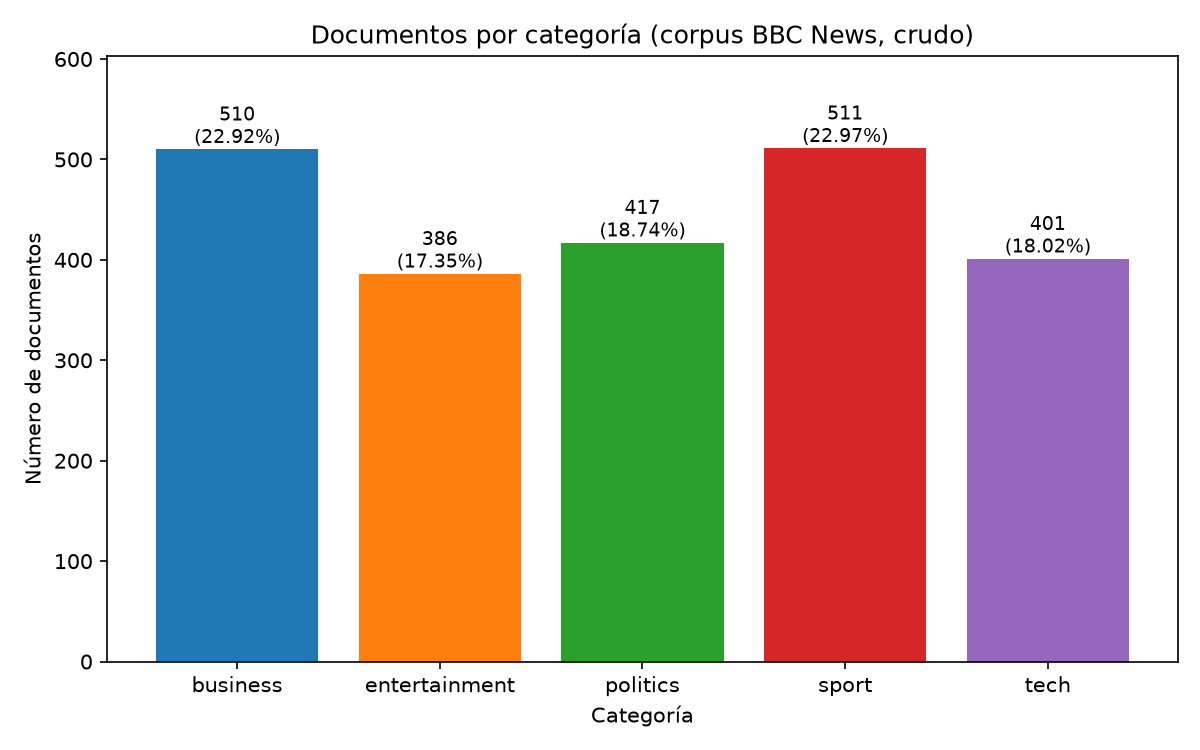

In [8]:
display(Image('reports/figuras/raw_categorias.png', width=700))

In [9]:
# Longitud en palabras, global y por categoría
pd.DataFrame(m_raw['longitud_palabras']).T.round(2)

,media,mediana,min,max,p25,p75
global,390.30,337.0,90.0,4492.0,250.00,479.00
business,334.19,303.0,142.0,912.0,236.00,395.75
entertainment,337.68,267.0,144.0,3570.0,228.25,367.75
politics,461.19,449.0,90.0,4492.0,320.00,536.00
sport,336.32,296.0,116.0,1671.0,208.00,415.50
tech,507.36,450.0,165.0,3007.0,340.00,633.00


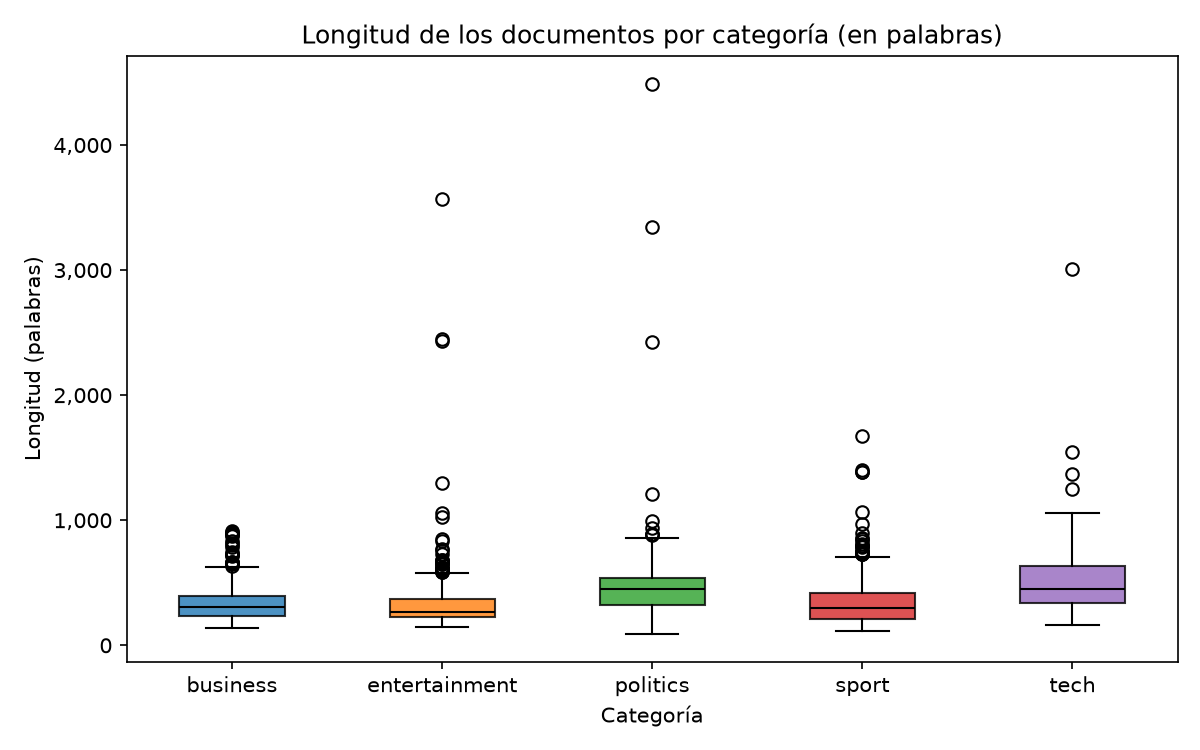

In [10]:
display(Image('reports/figuras/raw_longitudes.png', width=700))

In [11]:
simbolos = pd.Series({'dígitos': m_raw['pct_docs_con_digitos'], **m_raw['pct_docs_con_simbolo']}, name='% de documentos')
simbolos.map('{:.2f}%'.format).to_frame()

,% de documentos
dígitos,95.10%
£,29.08%
$,21.48%
%,28.31%
-,94.56%


**Hallazgos para la limpieza.** Hay 99 textos duplicados (54 de ellos en `tech`), que se eliminan conservando la primera aparición. Casi todos los documentos contienen dígitos y guiones; la etapa de limpieza los elimina y deja solo letras. El texto ya viene en minúsculas y sin acentos.

## 3. Limpieza, normalización y tokenización

`src/preprocesamiento.py` define **una sola función**, `preprocesar`, que se usa igual para el corpus, para noticias nuevas y para las consultas. `src/limpieza.py` la aplica al corpus: quita duplicados, descarta documentos con menos de 20 tokens y guarda `data/processed/corpus_clean.csv`.

In [12]:
from preprocesamiento import normalizar, tokenizar, preprocesar, STOPWORDS_EXTRA
import limpieza

# Cambia a True para regenerar el corpus limpio desde el CSV crudo (~35 s); el resultado es idéntico.
REEJECUTAR_LIMPIEZA = False
if REEJECUTAR_LIMPIEZA:
    limpieza.main()

m_limp = json.load(open('reports/limpieza.json'))
print(f"Documentos: {m_limp['n_antes']:,} -> {m_limp['n_despues']:,} | duplicados: {m_limp['duplicados']:,} | "
      f"descartados por cortos: {m_limp['descartados_cortos']:,} | tokens promedio: {m_limp['tokens_promedio']['antes']:,.2f} -> {m_limp['tokens_promedio']['despues']:,.2f}")
print('Stopwords propias:', STOPWORDS_EXTRA)

Documentos: 2,225 -> 2,126 | duplicados: 99 | descartados por cortos: 0 | tokens promedio: 390.45 -> 181.42
Stopwords propias: ['said', 'mr', 'mrs', 'ms', 'also', 'would', 'could', 'year', 'years', 'new', 'one', 'two']


In [13]:
# La misma función sirve para una consulta o un documento nuevo
ejemplo = 'The Markets were FALLING in 2005, said Mr Brown: shares lost £3bn!'
print('normalizar :', normalizar(ejemplo))
print('tokenizar  :', tokenizar(normalizar(ejemplo)))
print('lemma      :', preprocesar(ejemplo, modo='lemma'))
print('stem       :', preprocesar(ejemplo, modo='stem'))

normalizar : the markets were falling in said mr brown shares lost bn
tokenizar  : ['markets', 'falling', 'brown', 'shares', 'lost']
lemma      : ['market', 'fall', 'brown', 'share', 'lose']
stem       : ['market', 'fall', 'brown', 'share', 'lost']


In [14]:
corpus = pd.read_csv('data/processed/corpus_clean.csv')
print(f'{len(corpus):,} documentos, columnas: {list(corpus.columns)}')
corpus[['doc_id', 'category', 'titulo', 'tokens_lemma', 'n_tokens']].head()

2,126 documentos, columnas: ['doc_id', 'category', 'titulo', 'text_original', 'text_norm', 'tokens_lemma', 'tokens_stem', 'n_tokens']


,doc_id,category,titulo,tokens_lemma,n_tokens
0,doc_0000,tech,tv future in the hands of viewers with,future hand viewer home theatre system plasma highdefinition tvs digital vid...,329
1,doc_0001,business,worldcom boss left books alone former worldcom boss,worldcom boss leave books worldcom boss bernie ebber accuse oversee fraud ac...,151
2,doc_0002,sport,tigers wary of farrell gamble leicester say they,tiger wary farrell gamble leicester rush bid andy farrell great britain rugb...,98
3,doc_0003,sport,yeading face newcastle in fa cup premiership side,yeade face newcastle cup premiership newcastle united face trip ryman premie...,217
4,doc_0004,entertainment,ocean s twelve raids box office ocean s,ocean raids box office ocean crime caper sequel star george clooney brad pit...,141


In [15]:
resumen = corpus.groupby('category')['n_tokens'].agg(documentos='count', media='mean', mediana='median', minimo='min', maximo='max').round(2)
resumen

,documentos,media,mediana,minimo,maximo
category,,,,,
business,503,161.40,148.0,62,440
entertainment,369,161.44,131.0,69,1489
politics,403,210.15,208.0,40,1838
sport,504,153.02,128.5,51,779
tech,347,239.55,218.0,81,1213


**Decisiones.** Se eliminan dígitos y todo lo que no sea letra (los guiones se borran sin dejar espacio: `high-definition` queda como `highdefinition`), se quitan las stopwords de spaCy más la lista propia, y las etapas siguientes usan `tokens_lemma`. El detalle y los ejemplos están en `reports/limpieza.md`.